# APPLIED AI: Tutorial Neural Networks

Completed tutorial: run the cells in order. Use a Python environment with
`tensorflow`, `numpy`, `matplotlib`, and `scikit-learn` installed, or run in Google Colab.
The Fashion-MNIST data downloads the first time. Hyperparameter experiments take longer
than the baseline; set `RUN_EXPERIMENTS = False` in the experiment cell to skip them.

**PDF exercise — forward propagation.** The input weights are 3 and 1, and the bias is -1:
$z = 3x_1 + x_2 - 1$. The step activation returns 1 when $z \geq 10$, otherwise 0.
For (5, 10), $z=24$ and **y=1**. For (1, 2), $z=4$ and **y=0**.

**Evaluation:** use a training set to learn weights, a validation set to choose
hyperparameters, and the held-out test set for the final evaluation.


# TASK 1: CLASSIFICATION TASK



## 1) Download and load the Fashion-MNIST dataset

The code uses **Fashion-MNIST**, containing clothing images, rather than handwritten
MNIST digits. It provides 60,000 training images and 10,000 test images, each a
28 x 28 grayscale image. Labels 0–9 identify the ten clothing classes.

Dataset documentation: https://keras.io/api/datasets/fashion_mnist/


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

seed = 123
tf.keras.utils.set_random_seed(seed)
print('TensorFlow version:', tf.__version__)

fashion_mnist = tf.keras.datasets.fashion_mnist
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


TensorFlow version: 2.21.0


## 2) Split and visualise the first image in the train set

First 10 training labels: [9 0 0 3 0 2 7 2 5 5]


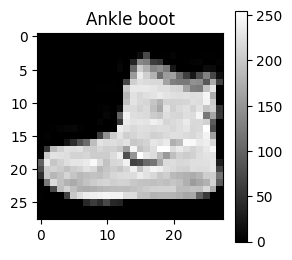

In [2]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()
print('First 10 training labels:', train_labels[:10])
plt.figure(figsize=(3, 3))
plt.imshow(train_images[0], cmap='gray')
plt.title(class_names[train_labels[0]])
plt.colorbar()
plt.grid(False)
plt.show()


#### **Question 1: How many images do you have in the train set and the in the test set? What is the size (in pixels) of the images?**
*Hint: You can use the .shape function and the len() function*

In [3]:
print('Training images:', len(train_images), '| shape:', train_images.shape)
print('Test images:', len(test_images), '| shape:', test_images.shape)
print('Image size:', train_images.shape[1:], '| pixels per image:', np.prod(train_images.shape[1:]))
# Answer: 60,000 training images, 10,000 test images, 28 x 28 = 784 pixels each.


Training images: 60000 | shape: (60000, 28, 28)
Test images: 10000 | shape: (10000, 28, 28)
Image size: (28, 28) | pixels per image: 784


#### **Question 2: How many images do you have for each class in the train set? Is it a balanced dataset?**

To answer this question, explore the data in train_labels. Each different label corresponds to a different class. You will have to count how many labels you have in the dataset for each class. The variable class_names has the names for each label in the same order (e.g., label in index 0 in class_names corresponds to label with value 0 in train_labels.

*Hint: The following code counts the number of values i in train_labels: np.count_nonzero(train_labels == i)*

In [4]:
class_counts = np.bincount(train_labels, minlength=len(class_names))
for name, count in zip(class_names, class_counts):
    print(f'{name:12s}: {count:,}')
print('Balanced:', bool(np.all(class_counts == class_counts[0])))
# Answer: each of the ten classes has 6,000 training images, so it is balanced.


T-shirt/top : 6,000
Trouser     : 6,000
Pullover    : 6,000
Dress       : 6,000
Coat        : 6,000
Sandal      : 6,000
Shirt       : 6,000
Sneaker     : 6,000
Bag         : 6,000
Ankle boot  : 6,000
Balanced: True


## 3) Visualise the first 25 images in the train set

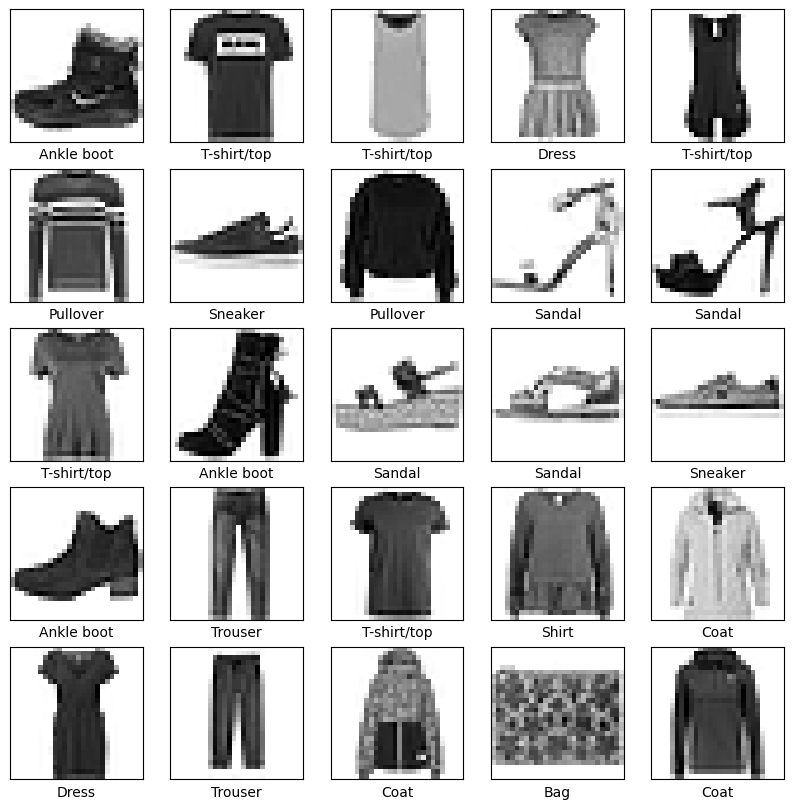

In [5]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

## 4) Prepare the inputs and create a neural network with TensorFlow

Divide pixel values by 255 to change the range from 0–255 to 0–1. This improves
numerical conditioning during optimisation. Reserve 10% of the original training
set for validation, with the same class proportions (stratification).

`Flatten` changes each 28 x 28 image into 784 inputs. The hidden dense layer has
128 ReLU units. The last layer has ten outputs called **logits**, one per class.
It has no activation because the loss below expects logits. The model contains
101,770 trainable parameters: (784 + 1) x 128 + (128 + 1) x 10.


In [6]:
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0
X_fit, X_val, y_fit, y_val = train_test_split(
    train_images, train_labels, test_size=0.1, random_state=seed, stratify=train_labels
)
print(f'Fit: {len(X_fit):,}; validation: {len(X_val):,}; test: {len(test_images):,}')

def build_classifier(units=(128,), learning_rate=0.001):
    network = tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        *[tf.keras.layers.Dense(width, activation='relu') for width in units],
        tf.keras.layers.Dense(10),
    ])
    network.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'],
    )
    return network

model = build_classifier()


Fit: 54,000; validation: 6,000; test: 10,000


## 5) Inspect the compiled model

The helper above compiles the model with Adam. Sparse categorical cross-entropy
is appropriate because each target is an integer class label. `from_logits=True`
matches the output layer. Accuracy measures the fraction of correct predictions.


In [7]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6) Train the model

In [8]:
epochs = 10
batch_size = 128
history = model.fit(
    X_fit, y_fit, validation_data=(X_val, y_val),
    epochs=epochs, batch_size=batch_size, verbose=2,
)


Epoch 1/10


422/422 - 6s - 15ms/step - accuracy: 0.8057 - loss: 0.5707 - val_accuracy: 0.8380 - val_loss: 0.4704


Epoch 2/10


422/422 - 2s - 4ms/step - accuracy: 0.8562 - loss: 0.4099 - val_accuracy: 0.8487 - val_loss: 0.4249


Epoch 3/10


422/422 - 3s - 6ms/step - accuracy: 0.8691 - loss: 0.3699 - val_accuracy: 0.8543 - val_loss: 0.4013


... (10 outputs left out)

Epoch 9/10


422/422 - 2s - 5ms/step - accuracy: 0.9011 - loss: 0.2718 - val_accuracy: 0.8763 - val_loss: 0.3417


Epoch 10/10


422/422 - 2s - 4ms/step - accuracy: 0.9041 - loss: 0.2624 - val_accuracy: 0.8752 - val_loss: 0.3382


## 7) Evaluate and plot learning progress

The plots use the separate validation set, not the test set. Baseline test
accuracy is reported for the tutorial; choose experiments using validation
accuracy only, without using test results to guide model changes.


In [9]:
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

print('\nTest accuracy:', test_acc)

313/313 - 1s - 3ms/step - accuracy: 0.8745 - loss: 0.3447



Test accuracy: 0.8744999766349792


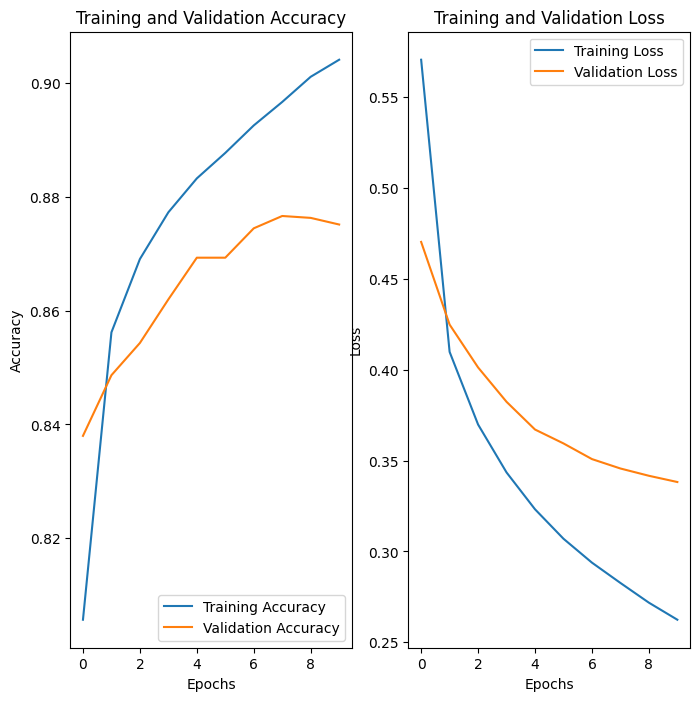

In [10]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

#### **Question 3: Is the validation accuracy higher or lower than the training accuracy at epoch 10? Why?**

**Answer (saved run):** at epoch 10, validation accuracy was **87.52%**, lower than training accuracy (**90.41%**). The network learns weights from the training examples, so performance on those examples can be better than on unseen validation examples. A widening gap is evidence of overfitting. The next cell calculates the comparison again if you rerun the notebook.

In [11]:
train_acc_10 = history.history['accuracy'][-1]
val_acc_10 = history.history['val_accuracy'][-1]
comparison = 'lower than' if val_acc_10 < train_acc_10 else ('higher than' if val_acc_10 > train_acc_10 else 'equal to')
print(f'Epoch 10 training accuracy: {train_acc_10:.2%}')
print(f'Epoch 10 validation accuracy: {val_acc_10:.2%} ({comparison} training accuracy)')

Epoch 10 training accuracy: 90.41%
Epoch 10 validation accuracy: 87.52% (lower than training accuracy)


#### **Question 4: Looking at the plot, do you think the accuracy could be improved? What would happen if we increase the number of epochs?**

**Answer (saved run):** the baseline reached 87.52% validation accuracy. Extending training to 50 epochs gave 87.70%, but 100 epochs dropped to 87.42%. Training accuracy rose from 90.41% to 98.03% by 100 epochs, while validation loss rose from 0.3382 to 0.7655. This is evidence of overfitting: more epochs improved the fit to training data without improving generalisation. The 256-unit model trained for 10 epochs performed better on validation data (87.82%). Early stopping on validation loss is a useful next improvement.

## 8) Get probabilities.

For each test image will tell us the probability to belong to each of the 10 classes (i.e., for each test image will output an array of 10 values).

Since our model returns the logits, we add a Softmax layer in order to convert logits to probabilities.

In [12]:
probability_model = tf.keras.Sequential([model, tf.keras.layers.Softmax()])
probabilities = probability_model.predict(test_images, verbose=0)
print('Probability array shape:', probabilities.shape)
print('First five probability vectors:')
print(np.round(probabilities[:5], 3))
print('Sum for each of the first five images:', probabilities[:5].sum(axis=1))


Probability array shape: (10000, 10)
First five probability vectors:
[[0.    0.    0.    0.    0.    0.002 0.    0.006 0.    0.992]
 [0.    0.    0.974 0.    0.002 0.    0.024 0.    0.    0.   ]
 [0.    1.    0.    0.    0.    0.    0.    0.    0.    0.   ]
 [0.    1.    0.    0.    0.    0.    0.    0.    0.    0.   ]
 [0.279 0.    0.05  0.011 0.027 0.    0.632 0.    0.001 0.   ]]
Sum for each of the first five images: [0.99999994 1.0000001  1.         1.0000001  0.99999994]


## 9) Get predicted class
For each image, we have a vector of 10 probabilities (1 for each possible class) that tells us the probability that that image belongs to the class. We now want to get the class with the highest probability. We use argmax to get the class with the highest probability

In [13]:
predictions = np.argmax(probabilities, axis=1)
print('Predictions shape:', predictions.shape)
print('First 20 predictions:', predictions[:20])
print('First 20 true labels:', test_labels[:20])
# argmax returns the index of the largest probability, which is the predicted label.


Predictions shape: (10000,)
First 20 predictions: [9 2 1 1 6 1 4 6 5 7 4 5 5 3 4 1 2 2 8 0]
First 20 true labels: [9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]


## 10) Final accuracy (test set)

In [14]:
accuracy_test = np.count_nonzero(predictions==test_labels)/len(test_images)
print('The accuracy on the test set is: ' + str(accuracy_test))

The accuracy on the test set is: 0.8745


## 11) Results
Predicted class of first image:

In [15]:
class_names[predictions[0]]

'Ankle boot'

We willl use the following function to plot the results

In [16]:
def plot_image(i, predictions_array, true_label, img):
  true_label, img = true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  true_label = true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

We will now use the functions to visualise the first 5 images and the predictedclass:

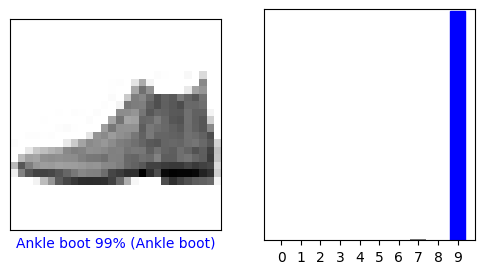

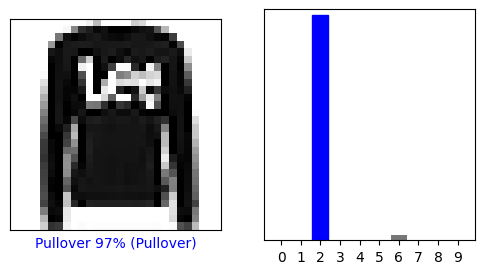

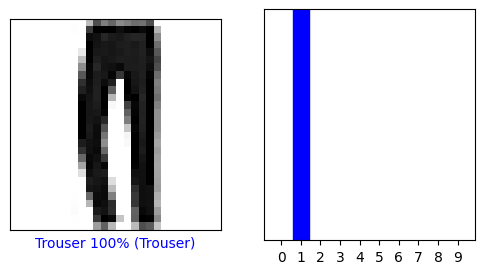

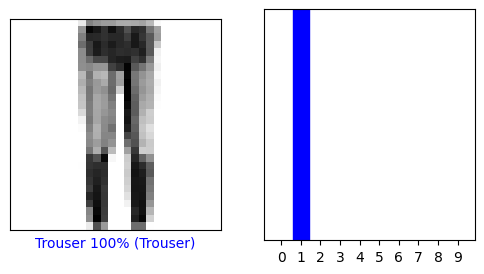

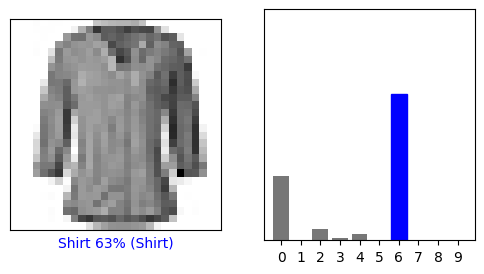

In [17]:
for i in range(5):
    plt.figure(figsize=(6,3))
    plt.subplot(1,2,1)
    plot_image(i, probabilities[i], test_labels, test_images)
    plt.subplot(1,2,2)
    plot_value_array(i, probabilities[i],  test_labels)
    plt.show()

#### **Question 5: Did the model predict the first five classes correctly? Which prediction has the lowest confidence, and why?**

The original question says "predicted accuracy". For a single image, the largest
predicted probability is **confidence**; accuracy is measured across labelled examples.


**Answer (saved run):** all five predictions were correct: ankle boot, pullover, trouser, trouser and shirt. The fifth image (index 4) had the lowest confidence: **63.16% for Shirt**, with **27.92% for T-shirt/top**. These similar clothing categories explain the ambiguity seen in this image and its probability chart. Confidence is the largest predicted class probability; it is not a separate accuracy measure for one image. The next cell recalculates these results on each run.

In [18]:
first_five_confidence = probabilities[:5].max(axis=1)
for i in range(5):
    print(f'{i}: actual={class_names[test_labels[i]]}, predicted={class_names[predictions[i]]}, '
          f'confidence={first_five_confidence[i]:.2%}, correct={predictions[i] == test_labels[i]}')
lowest = int(np.argmin(first_five_confidence))
print('All first five correct:', bool(np.all(predictions[:5] == test_labels[:5])))
print(f'Lowest confidence: image index {lowest}, predicted {class_names[predictions[lowest]]}')
top_two = np.argsort(probabilities[lowest])[-2:][::-1]
print('Top two classes:', [(class_names[k], float(probabilities[lowest, k])) for k in top_two])

0: actual=Ankle boot, predicted=Ankle boot, confidence=99.18%, correct=True
1: actual=Pullover, predicted=Pullover, confidence=97.37%, correct=True
2: actual=Trouser, predicted=Trouser, confidence=100.00%, correct=True
3: actual=Trouser, predicted=Trouser, confidence=99.98%, correct=True
4: actual=Shirt, predicted=Shirt, confidence=63.16%, correct=True
All first five correct: True
Lowest confidence: image index 4, predicted Shirt
Top two classes: [('Shirt', 0.6316096186637878), ('T-shirt/top', 0.27922216057777405)]


## Hyperparameter experiments

Change one setting at a time from the baseline (10 epochs, learning rate 0.001,
one hidden layer with 128 units). Compare 50 and 100 epochs, learning rates 0.01
and 0.0001, 256 hidden units, and an additional 64-unit hidden layer.

Each experiment starts with fresh weights and the same seed, split and batch size.
**Rank by final validation accuracy**, not test accuracy. Plot both accuracy and
loss to check for overfitting. The saved final-epoch models match the reported
final-epoch scores; this exercise does not select the best checkpoint within a run.


baseline: validation accuracy=87.52%, validation loss=0.3382; 0.0s (baseline reuses its existing fit)


epochs_50: validation accuracy=87.70%, validation loss=0.4998; 96.6s (baseline reuses its existing fit)


epochs_100: validation accuracy=87.42%, validation loss=0.7655; 129.5s (baseline reuses its existing fit)


lr_0.01: validation accuracy=86.17%, validation loss=0.3994; 13.8s (baseline reuses its existing fit)


lr_0.0001: validation accuracy=85.40%, validation loss=0.4149; 13.8s (baseline reuses its existing fit)


units_256: validation accuracy=87.82%, validation loss=0.3307; 16.8s (baseline reuses its existing fit)


extra_layer: validation accuracy=87.68%, validation loss=0.3473; 14.4s (baseline reuses its existing fit)



Experiment     Epochs       LR Hidden units  Train acc    Val acc   Val loss
units_256          10    0.001       (256,)     91.39%     87.82%     0.3307
epochs_50          50    0.001       (128,)     96.27%     87.70%     0.4998
extra_layer        10    0.001    (128, 64)     90.79%     87.68%     0.3473
baseline           10    0.001       (128,)     90.41%     87.52%     0.3382
epochs_100        100    0.001       (128,)     98.03%     87.42%     0.7655
lr_0.01            10     0.01       (128,)     88.78%     86.17%     0.3994
lr_0.0001          10   0.0001       (128,)     86.60%     85.40%     0.4149


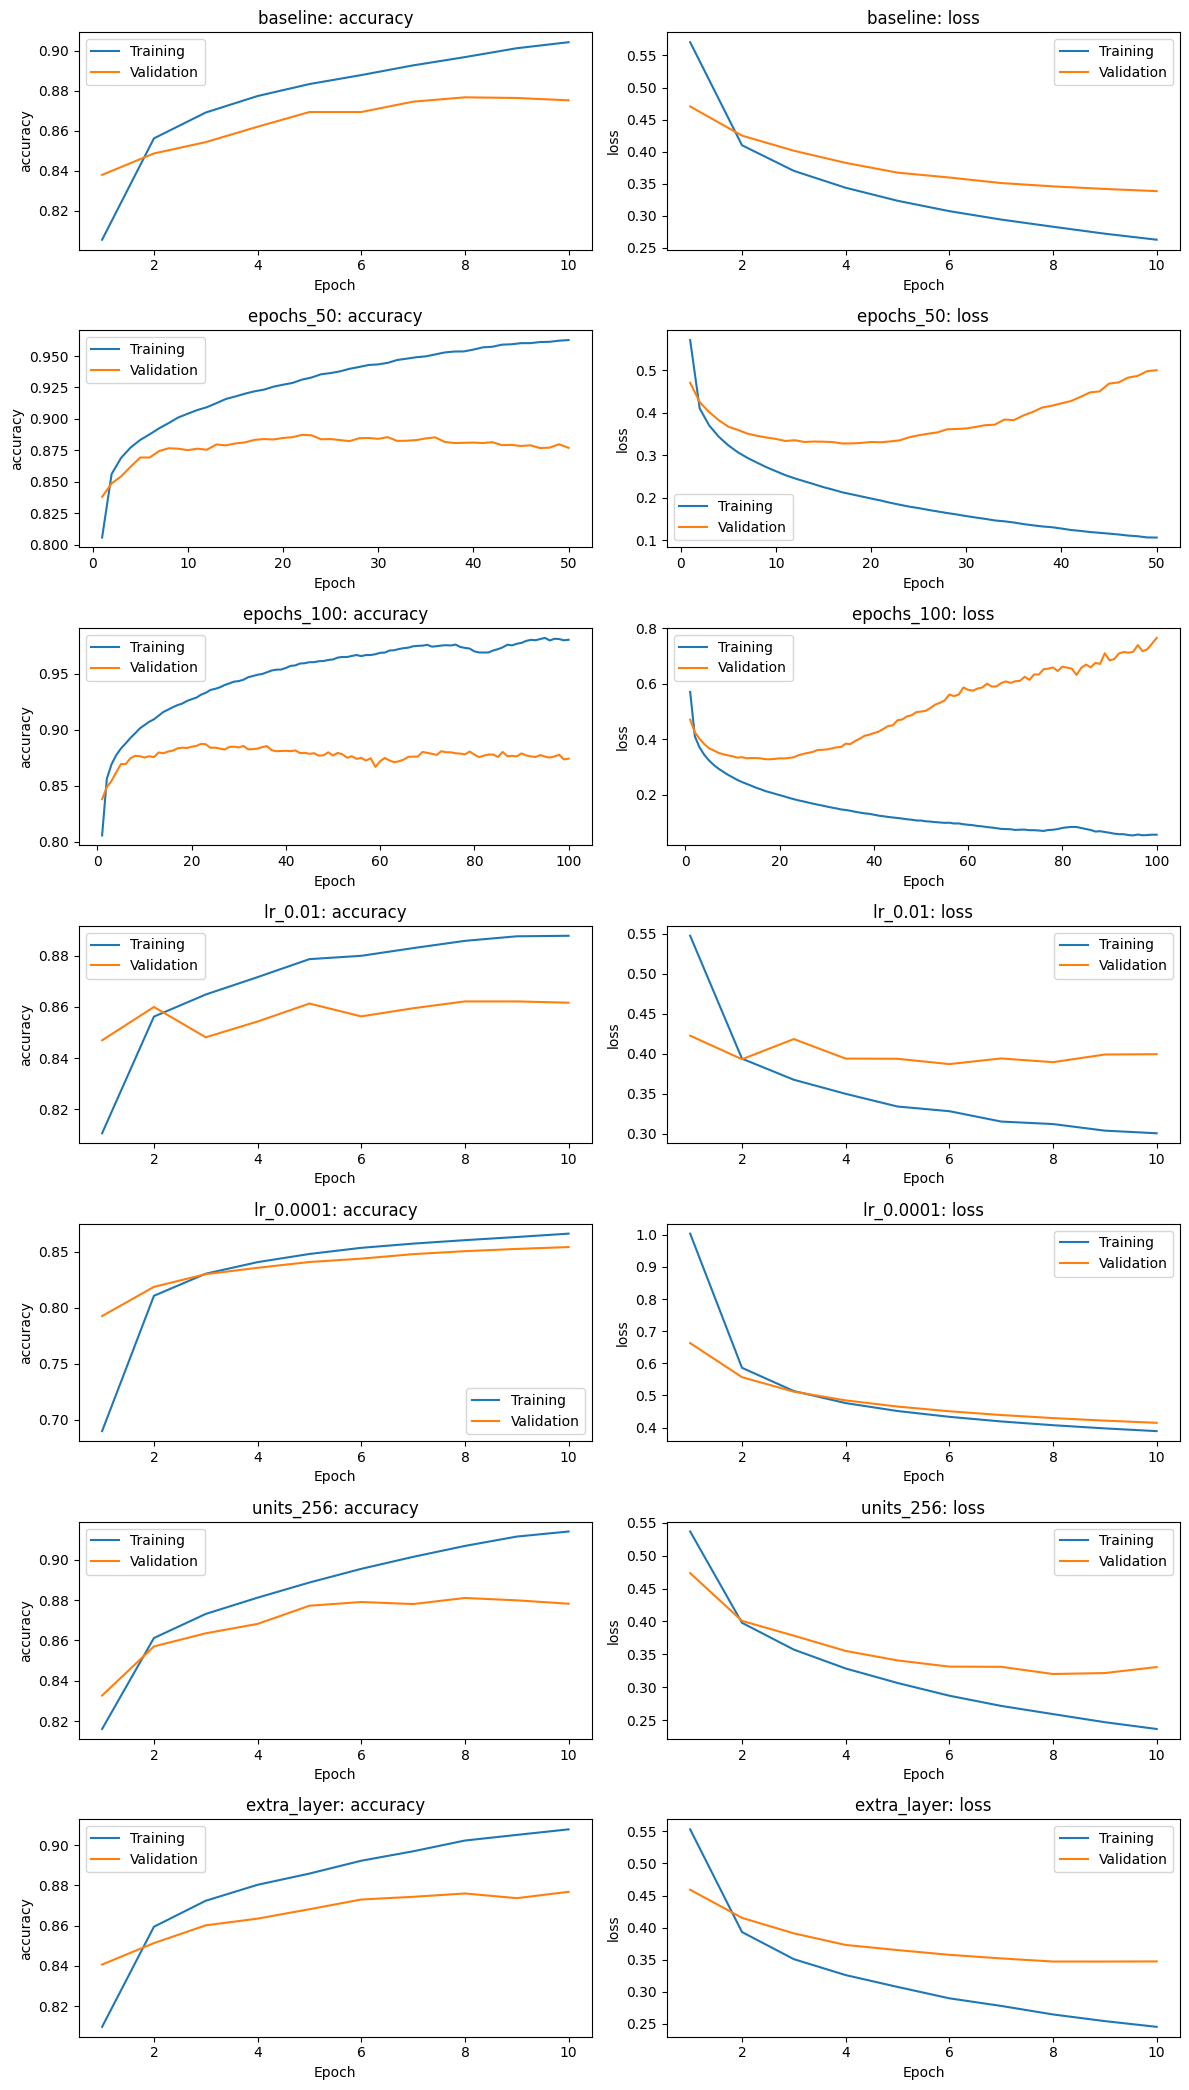

In [19]:
import time

RUN_EXPERIMENTS = True
experiments = [
    ('baseline', 10, 0.001, (128,)),
    ('epochs_50', 50, 0.001, (128,)),
    ('epochs_100', 100, 0.001, (128,)),
    ('lr_0.01', 10, 0.01, (128,)),
    ('lr_0.0001', 10, 0.0001, (128,)),
    ('units_256', 10, 0.001, (256,)),
    ('extra_layer', 10, 0.001, (128, 64)),
]
experiment_results = []
experiment_histories = {}
best_classifier = model
best_name = 'baseline'
best_val_accuracy = -1.0

for name, run_epochs, learning_rate, units in experiments:
    if not RUN_EXPERIMENTS and name != 'baseline':
        continue
    start = time.perf_counter()
    if name == 'baseline':
        candidate, run_history = model, history
    else:
        tf.keras.utils.set_random_seed(seed)
        candidate = build_classifier(units, learning_rate)
        run_history = candidate.fit(
            X_fit, y_fit, validation_data=(X_val, y_val),
            epochs=run_epochs, batch_size=batch_size, verbose=0,
        )
    scores = run_history.history
    final_val = scores['val_accuracy'][-1]
    experiment_histories[name] = scores
    experiment_results.append({
        'name': name, 'epochs': run_epochs, 'lr': learning_rate, 'units': units,
        'train_accuracy': scores['accuracy'][-1],
        'val_accuracy': final_val, 'val_loss': scores['val_loss'][-1],
    })
    if final_val > best_val_accuracy:
        best_val_accuracy, best_classifier, best_name = final_val, candidate, name
    print(f'{name}: validation accuracy={final_val:.2%}, '
          f'validation loss={scores["val_loss"][-1]:.4f}; '
          f'{time.perf_counter() - start:.1f}s (baseline reuses its existing fit)', flush=True)

print()
print(f'{"Experiment":<14} {"Epochs":>6} {"LR":>8} {"Hidden units":>12} {"Train acc":>10} {"Val acc":>10} {"Val loss":>10}')
for row in sorted(experiment_results, key=lambda row: row['val_accuracy'], reverse=True):
    print(f'{row["name"]:<14} {row["epochs"]:>6} {row["lr"]:>8g} '
          f'{str(row["units"]):>12} {row["train_accuracy"]:>10.2%} '
          f'{row["val_accuracy"]:>10.2%} {row["val_loss"]:>10.4f}')

fig, axes = plt.subplots(len(experiment_histories), 2,
                         figsize=(12, 3 * len(experiment_histories)), squeeze=False)
for (name, scores), row_axes in zip(experiment_histories.items(), axes):
    for ax, metric in zip(row_axes, ('accuracy', 'loss')):
        steps = np.arange(1, len(scores[metric]) + 1)
        ax.plot(steps, scores[metric], label='Training')
        ax.plot(steps, scores['val_' + metric], label='Validation')
        ax.set(title=f'{name}: {metric}', xlabel='Epoch', ylabel=metric)
        ax.legend()
plt.tight_layout()
plt.show()

#### **Which hyperparameters provided the best accuracy?**

**Answer (saved run):** among the seven tested settings, **256 hidden units, learning rate 0.001 and 10 epochs** gave the highest final validation accuracy (**87.82%**) and a final test accuracy of **87.72%**. The baseline test accuracy was 87.45%.

Increasing the number of epochs produced the clearest overfitting: the 100-epoch model reached 98.03% training accuracy but only 87.42% validation accuracy. Both tested learning-rate changes reduced validation accuracy compared with the baseline. Adding a second hidden layer gave a smaller gain than increasing the first hidden layer to 256 units.

These are results for one split and seed, not a universal best configuration. Differences of a few tenths of a percentage point are small; repeat with other seeds for stronger evidence. The next cell reports the selected model again on each run.

In [20]:
best_test_loss, best_test_accuracy = best_classifier.evaluate(test_images, test_labels, verbose=0)
print('Best configuration by final validation accuracy:', best_name)
winner = next(row for row in experiment_results if row['name'] == best_name)
print(f'Epochs: {winner["epochs"]}; learning rate: {winner["lr"]}; hidden units: {winner["units"]}')
print(f'Validation accuracy: {best_val_accuracy:.2%}')
print(f'Selected model test accuracy: {best_test_accuracy:.2%}')
print(f'Selected model test loss: {best_test_loss:.4f}')
if not RUN_EXPERIMENTS:
    print('Only the baseline was run; enable RUN_EXPERIMENTS for a comparison.')

Best configuration by final validation accuracy: units_256
Epochs: 10; learning rate: 0.001; hidden units: (256,)
Validation accuracy: 87.82%
Selected model test accuracy: 87.72%
Selected model test loss: 0.3486


# TASK 2: REGRESSION TASK

Predict the next day's temperature from the previous five days using synthetic
sine-wave data. A single linear output predicts a continuous temperature, while
the classification model produces ten class scores. These simulated results do
not establish performance on real weather.


## 1) Create a synthetic dataset

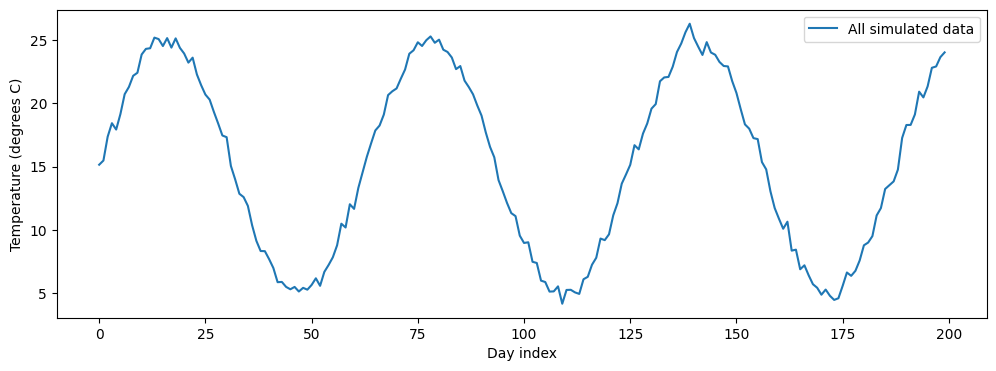

In [21]:
tf.keras.utils.set_random_seed(42)
rng = np.random.default_rng(42)
data = (np.sin(np.linspace(0, 20, 200)) + rng.normal(scale=0.05, size=200)) * 10 + 15

plt.figure(figsize=(12, 4))
plt.plot(data, label='All simulated data')
plt.xlabel('Day index')
plt.ylabel('Temperature (degrees C)')
plt.legend()
plt.show()


## 2) Create the train and tests sets

In [22]:
window_size = 5
X = np.array([data[i:i + window_size] for i in range(len(data) - window_size)], dtype='float32')
y = np.array([data[i + window_size] for i in range(len(data) - window_size)], dtype='float32')
train_size = int(0.8 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]
print('Input/target shapes:', X.shape, y.shape)
print('Training examples:', len(X_train), '| test examples:', len(X_test))
# 195 windows: 156 training examples and 39 test examples.
# Keep time order so future targets never enter the training set. Consecutive
# windows share past observations, as in a rolling one-day-ahead forecast.


Input/target shapes: (195, 5) (195,)
Training examples: 156 | test examples: 39


## 3) Visualise a sample of the dataset

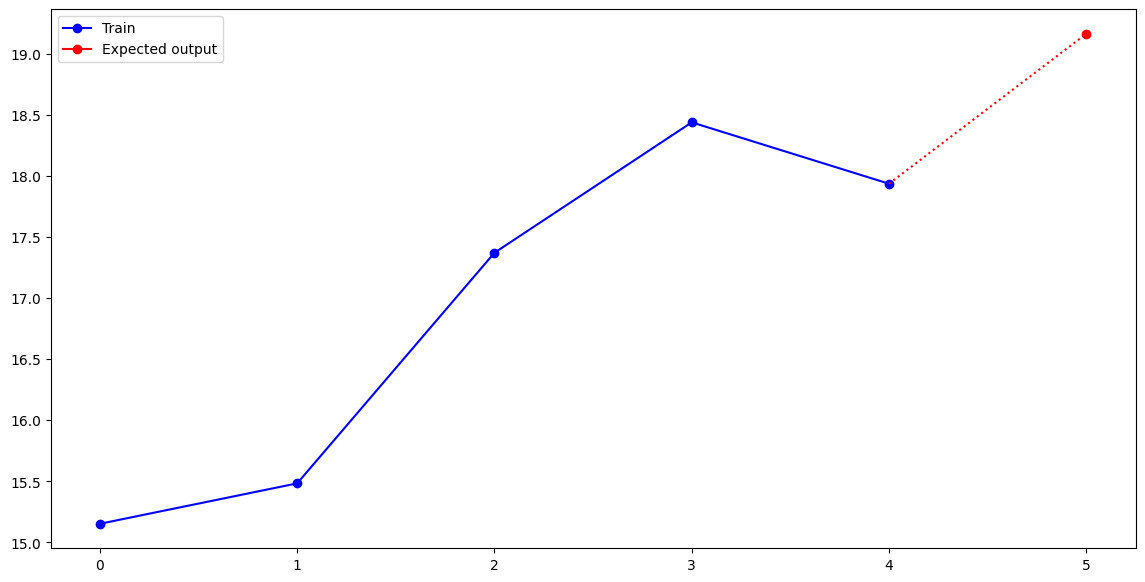

In [23]:
# Plotting the data
plt.figure(figsize=(14, 7))
plt.plot(X_train[0], label='Train', color='blue', marker='o') # train data
plt.plot(5,y_train[0], label='Expected output', color='red', marker='o') # output
plt.plot([4, 5], [X[0][-1], y[0]], linestyle='dotted', color='red') # dotted line, for visualisation purposes only
plt.legend()

The blue line represents a sample of the temperature from the previous 5 days used during training. The red dot is the real value representing the temperature of the 6th day (the value to be predicted).

## 4) Create a neural network to make the prediction (regression)



Final training MSE: 0.4241943061351776
Final validation MSE: 0.42265185713768005


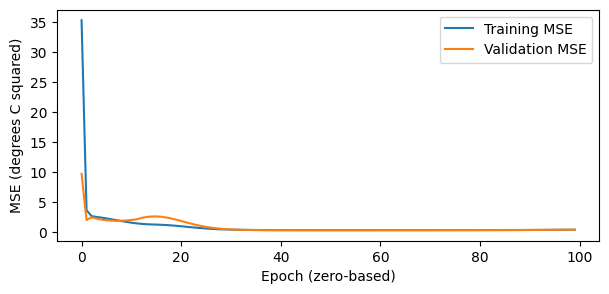

In [24]:
regression_model = tf.keras.Sequential([
    tf.keras.Input(shape=(window_size,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1),
])
regression_model.compile(optimizer='adam', loss='mse')
regression_history = regression_model.fit(
    X_train, y_train, epochs=100, batch_size=4,
    validation_split=0.1, shuffle=False, verbose=0,
)
print('Final training MSE:', regression_history.history['loss'][-1])
print('Final validation MSE:', regression_history.history['val_loss'][-1])
plt.figure(figsize=(7, 3))
plt.plot(regression_history.history['loss'], label='Training MSE')
plt.plot(regression_history.history['val_loss'], label='Validation MSE')
plt.xlabel('Epoch (zero-based)')
plt.ylabel('MSE (degrees C squared)')
plt.legend()
plt.show()


## 5) Evaluate the regression model

Regression uses error measures rather than classification accuracy. Lower MSE
is better. RMSE is in degrees C and is easier to interpret. Compare with a
**persistence baseline** that predicts tomorrow equals the most recent day.


In [25]:
predicted_temp = regression_model.predict(X_test, verbose=0).ravel()


Let's visualise how good are the predictions (visually):

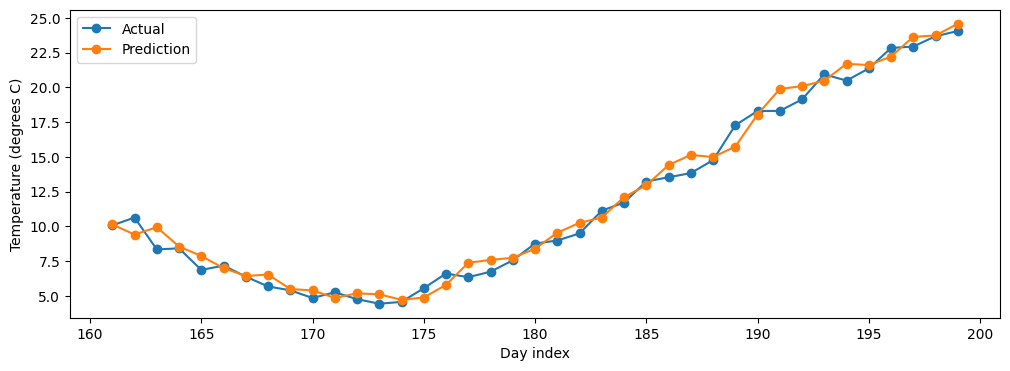

In [26]:
test_days = np.arange(window_size + train_size, len(data))
plt.figure(figsize=(12, 4))
plt.plot(test_days, y_test, label='Actual', marker='o')
plt.plot(test_days, predicted_temp, label='Prediction', marker='o')
plt.xlabel('Day index')
plt.ylabel('Temperature (degrees C)')
plt.legend()
plt.show()


#### **Question 6: Calculate the Mean Squared Error (MSE) of the model**

*Hint: You can use the function mean_squared_error from sklearn.metrics*

In [27]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, predicted_temp)
baseline_mse = mean_squared_error(y_test, X_test[:, -1])
print(f'Test MSE: {mse:.4f} degrees C squared')
print(f'Test RMSE: {np.sqrt(mse):.4f} degrees C')
print(f'Persistence baseline MSE: {baseline_mse:.4f} degrees C squared')
print('Neural network beats persistence baseline:', mse < baseline_mse)
# MSE = mean((actual temperature - predicted temperature) ** 2).


Test MSE: 0.5793 degrees C squared
Test RMSE: 0.7611 degrees C
Persistence baseline MSE: 0.9472 degrees C squared
Neural network beats persistence baseline: True


**Question 6 answer (saved run):** the regression model achieved a test **MSE of 0.5793 degrees C squared**, equivalent to an **RMSE of 0.7611 degrees C**. Its MSE was lower than the persistence baseline (0.9472), which predicts tomorrow equals the latest temperature. MSE is the average squared difference between predicted and actual temperatures; lower is better. These results describe synthetic data rather than real weather.

## 6) User interaction

Extend the code such that you now ask the user to input the temperature of the last 5 days, and use the model to tell the user the temperature of the following day

In [28]:
def predict_next_temperature(last_five_days):
    values = np.asarray(last_five_days, dtype='float32')
    if values.shape != (window_size,) or not np.isfinite(values).all():
        raise ValueError('Provide exactly five finite temperatures, oldest to newest.')
    return float(regression_model.predict(values.reshape(1, window_size), verbose=0)[0, 0])

def ask_for_temperatures():
    while True:
        raw = input('Enter the last 5 temperatures in degrees C, oldest to newest (comma or space separated): ')
        try:
            values = [float(value) for value in raw.replace(',', ' ').split()]
            prediction = predict_next_temperature(values)
        except (ValueError, OverflowError):
            print('Please enter exactly five finite numbers, e.g. 18, 19, 20, 21, 22.')
            continue
        print(f'Predicted next-day temperature: {prediction:.2f} degrees C')
        return prediction

# Demonstrate without blocking Run All. For the requested interactive prompt,
# uncomment the next line and run this cell:
# ask_for_temperatures()
example = [18, 19, 20, 21, 22]
print(f'Example input: {example}')
print(f'Predicted next-day temperature: {predict_next_temperature(example):.2f} degrees C')


Example input: [18, 19, 20, 21, 22]


Predicted next-day temperature: 23.16 degrees C


# OPTIONAL — Challenge

Choose a new dataset from https://www.tensorflow.org/datasets/catalog/overview
and repeat the train/validation/test process. For example, a CIFAR-10 experiment
needs input shape (32, 32, 3), normalisation, and ten output logits. Compare
epochs, learning rate and hidden units using validation accuracy, then evaluate
the selected model on the held-out test set. This extension is optional and is
not included in the measured Fashion-MNIST experiments above.
